In [ ]:
!pip install torch torchvision torchaudio
!pip install scikit-learn seaborn tqdm matplotlib


In [ ]:
DATA_ROOT = '/content/drive/MyDrive/Colab Notebooks/Domain Adaptation'


In [ ]:
!python "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/dann_vgg16.py" \
  --source-dir "$DATA_ROOT/ISIC2019_merged" \
  --target-dir "$DATA_ROOT/fitz_unlabeled/dummy" \
  --test-dir "$DATA_ROOT/fitz_selected" \
  --out-dir /content/drive/MyDrive/Colab\ Results/DANN_VGG16 \
  --epochs 30 \
  --batch-size 16 \
  --iters-per-epoch 300 \
  --lr 1e-4 \
  --lambda-val 1.0


Loading datasets...
Building model...
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_BN_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_BN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/vgg16_bn-6c64b313.pth" to /root/.cache/torch/hub/checkpoints/vgg16_bn-6c64b313.pth
100% 528M/528M [00:02<00:00, 217MB/s]
Training DANN...
DANN Train Ep 1/30: 100% 300/300 [17:15<00:00,  3.45s/it, cls=1.38, dom=0.639, loss=2.02]
DANN Train Ep 2/30: 100% 300/300 [16:33<00:00,  3.31s/it, cls

In [ ]:
import pandas as pd
report_path = '/content/drive/MyDrive/Colab Results/DANN_VGG16/classification_report.csv'
df = pd.read_csv(report_path, index_col=0)
display(df.head())


,precision,recall,f1-score,support
ak,0.183333,0.062857,0.093617,175.0
bcc,0.538244,0.380000,0.445487,500.0
bkl,0.030120,0.072464,0.042553,69.0
df,0.357143,0.063291,0.107527,79.0
mel,0.398633,0.350000,0.372737,500.0


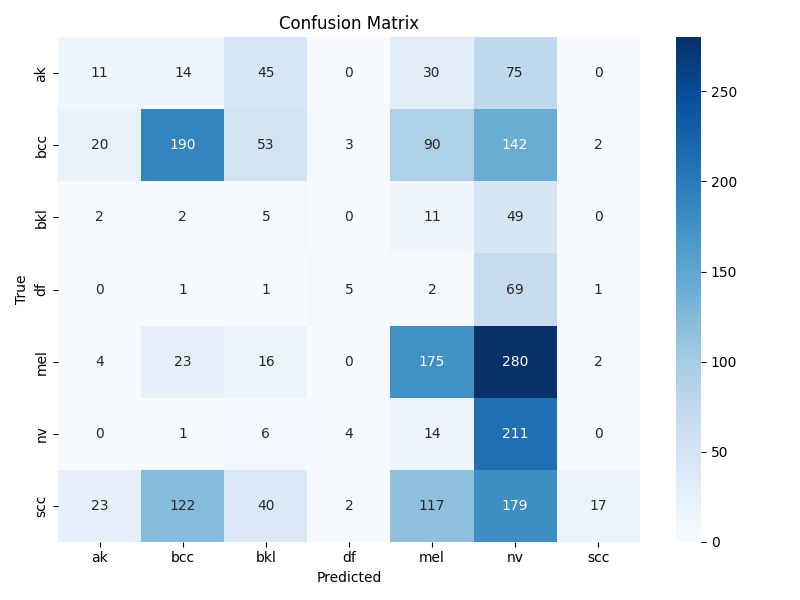

In [ ]:
from IPython.display import Image
Image('/content/drive/MyDrive/Colab Results/DANN_VGG16/confusion_matrix.png')


In [ ]:
!cp -r /content/drive/MyDrive/Colab\ Results/DANN_VGG16 \


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch

# Your test dataset path
test_dir = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected"  # adjust if needed

# Use the same transform as during training
val_tfm = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

# Recreate test dataset + loader
test_ds = datasets.ImageFolder(test_dir, transform=val_tfm)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False)
classes = test_ds.classes
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Test loader rebuilt successfully!")
print("Classes:", classes)


✅ Test loader rebuilt successfully!
Classes: ['ak', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc']


In [ ]:
# make sure both encoder and classifier are on the same device
encoder = encoder.to(device)
classifier = classifier.to(device)

# check they are both cuda if available
print("Encoder device:", next(encoder.parameters()).device)
print("Classifier device:", next(classifier.parameters()).device)


Encoder device: cuda:0
Classifier device: cuda:0


Showing predictions for each class...


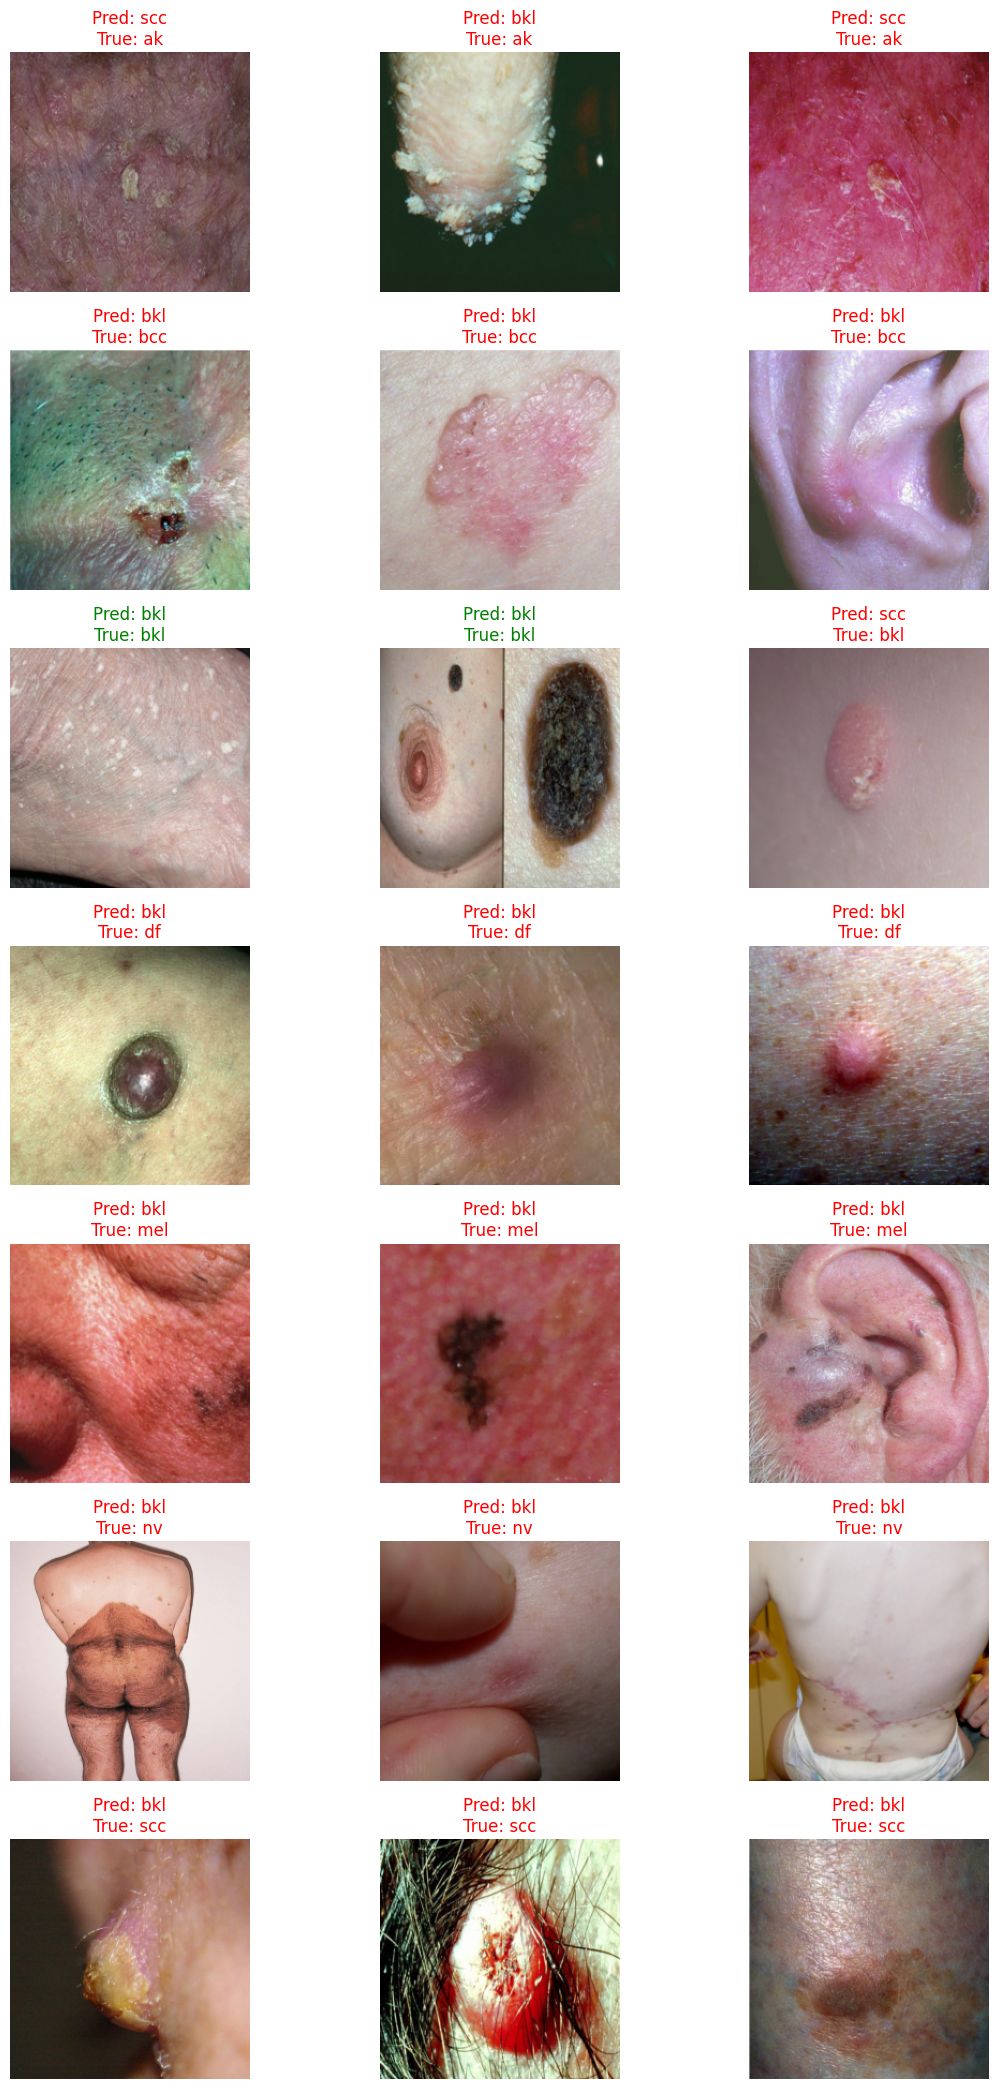

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# 🎨 Function to show predictions per class
def show_predictions(encoder, classifier, dataloader, class_names, device, n_samples=2):
    encoder.eval()
    classifier.eval()
    samples_per_class = {cls: 0 for cls in class_names}
    shown_images = []

    with torch.no_grad():
        for imgs, labels in dataloader:
            imgs, labels = imgs.to(device), labels.to(device)
            feats = encoder(imgs)
            outputs = classifier(feats)
            _, preds = torch.max(outputs, 1)

            for img, pred, label in zip(imgs, preds, labels):
                cls_name = class_names[label.item()]
                if samples_per_class[cls_name] < n_samples:
                    samples_per_class[cls_name] += 1
                    shown_images.append((img.cpu(), label.item(), pred.item()))
            if all(v >= n_samples for v in samples_per_class.values()):
                break

    rows = len(class_names)
    plt.figure(figsize=(n_samples * 4, rows * 3))
    for idx, (img, label, pred) in enumerate(shown_images):
        img_np = img.permute(1, 2, 0).numpy()
        img_np = np.clip((img_np * [0.229, 0.224, 0.225]) + [0.485, 0.456, 0.406], 0, 1)
        plt.subplot(rows, n_samples, idx + 1)
        plt.imshow(img_np)
        plt.axis("off")
        color = "green" if label == pred else "red"
        plt.title(f"Pred: {class_names[pred]}\nTrue: {class_names[label]}", color=color)
    plt.tight_layout()
    plt.show()

# Run visualization
print("Showing predictions for each class...")
show_predictions(encoder, classifier, test_loader, classes, device, n_samples=3)
